## Lab 2

### Part 3. Poetry generation

Let's try to generate some poetry using RNNs.

You have several choices here:

* The Shakespeare sonnets, file `sonnets.txt` available in the notebook directory.

* Роман в стихах "Евгений Онегин" Александра Сергеевича Пушкина. В предобработанном виде доступен по [ссылке](https://github.com/attatrol/data_sources/blob/master/onegin.txt).

* Some other text source, if it will be approved by the course staff.

Text generation can be designed in several steps:
    
1. Data loading.
2. Dictionary generation.
3. Data preprocessing.
4. Model (neural network) training.
5. Text generation (model evaluation).


In [1]:
import string
import os

### Data loading: Shakespeare

Shakespeare sonnets are awailable at this [link](http://www.gutenberg.org/ebooks/1041?msg=welcome_stranger). In addition, they are stored in the same directory as this notebook (`sonnetes.txt`). Simple preprocessing is already done for you in the next cell: all technical info is dropped.

In [3]:
if not os.path.exists('sonnets.txt'):
    !wget https://raw.githubusercontent.com/girafe-ai/ml-course/22f_basic/homeworks_basic/lab02_deep_learning/sonnets.txt

with open('sonnets.txt', 'r') as iofile:
    text = iofile.readlines()

TEXT_START = 45
TEXT_END = -368
text = text[TEXT_START : TEXT_END]
assert len(text) == 2616

In opposite to the in-class practice, this time we want to predict complex text. Let's reduce the complexity of the task and lowercase all the symbols.

Now variable `text` is a list of strings. Join all the strings into one and lowercase it.

In [4]:
# Join all the strings into one and lowercase it
# Put result into variable text.

text = ''.join(text).lower()

assert len(text) == 100225, 'Are you sure you have concatenated all the strings?'
assert not any([x in set(text) for x in string.ascii_uppercase]), 'Uppercase letters are present'
print('OK!')

OK!


### Data loading: "Евгений Онегин"


In [ ]:
!wget https://raw.githubusercontent.com/attatrol/data_sources/master/onegin.txt

with open('onegin.txt', 'r') as iofile:
    text = iofile.readlines()

text = [x.replace('\t\t', '') for x in text]

--2020-05-10 19:02:32--  https://raw.githubusercontent.com/attatrol/data_sources/master/onegin.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 151.101.244.133
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|151.101.244.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 262521 (256K) [text/plain]
Saving to: ‘onegin.txt’

onegin.txt          100%[===================>] 256.37K  --.-KB/s    in 0.1s    

2020-05-10 19:02:33 (2.25 MB/s) - ‘onegin.txt’ saved [262521/262521]



In opposite to the in-class practice, this time we want to predict complex text. Let's reduce the complexity of the task and lowercase all the symbols.

Now variable `text` is a list of strings. Join all the strings into one and lowercase it.

In [ ]:
# Join all the strings into one and lowercase it
# Put result into variable text.

# Your great code here


Put all the characters, that you've seen in the text, into variable `tokens`.

In [5]:
tokens = sorted(set(text))
num_tokens = len(tokens)
print('number of tokens:', num_tokens)

number of tokens: 38


Create dictionary `token_to_idx = {<char>: <index>}` and dictionary `idx_to_token = {<index>: <char>}`

In [6]:
# dict <index>:<char>
idx_to_token = {index: token for index, token in enumerate(tokens)}

# dict <char>:<index>
token_to_idx = {token: index for index, token in enumerate(tokens)}

*Comment: in this task we have only 38 different tokens, so let's use one-hot encoding.*

### Building the model


Now we want to build and train recurrent neural net which would be able to something similar to Shakespeare's poetry.

Let's use vanilla RNN, similar to the one created during the lesson.

In [18]:
import torch
from torch import nn
from torch.nn import functional as F

class CharRNN(nn.Module):
    def __init__(self, num_tokens=38, hidden_size=128):
        super(self.__class__, self).__init__()
        self.num_tokens = num_tokens
        self.hidden_size = hidden_size

        self.rnn_update = nn.Linear(num_tokens + hidden_size, hidden_size)
        self.head = nn.Linear(hidden_size, num_tokens)

    def forward(self, x, h_prev):
        x_one_hot = F.one_hot(x, self.num_tokens).float()
        h_next = torch.tanh(self.rnn_update(torch.cat([x_one_hot, h_prev], dim=-1)))
        logits = self.head(h_next)
        return logits, h_next

    def initial_state(self, batch_size, device='cpu'):

        return torch.zeros(batch_size, self.hidden_size, device=device)

In [ ]:
SEQ_LENGTH = 100
text_ids = torch.tensor([token_to_idx[token] for token in text], dtype=torch.int64)
n_chunks = len(text_ids) // (SEQ_LENGTH + 1)
chunks = text_ids[:n_chunks * (SEQ_LENGTH + 1)].view(n_chunks, SEQ_LENGTH + 1)

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
char_rnn = CharRNN().to(device)
opt = torch.optim.Adam(char_rnn.parameters(), lr=2e-3)
loss_func = nn.CrossEntropyLoss()

n_epoch = 1000
batch_size = 128
loss_history = []

for epoch in range(n_epoch):
    perm = torch.randperm(n_chunks)
    epoch_loss, n_batches = 0., 0

    for start in range(0, n_chunks, batch_size):
        batch = chunks[perm[start:start + batch_size]].to(device)
        hid_state = char_rnn.initial_state(batch.shape[0], device=device)

        logits_seq = []
        for t in range(SEQ_LENGTH):
            logits, hid_state = char_rnn(batch[:, t], hid_state)
            logits_seq.append(logits)
        logits_seq = torch.stack(logits_seq, dim=1)

        loss = loss_func(logits_seq.reshape(-1, len(tokens)), batch[:, 1:].reshape(-1))

        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(char_rnn.parameters(), 5.)
        opt.step()

        epoch_loss += loss.item()
        n_batches += 1

    loss_history.append(epoch_loss / n_batches)
    print(f'epoch {epoch + 1:2d} | loss {loss_history[-1]:.4f}')

epoch  1 | loss 3.3689
epoch  2 | loss 3.0021
epoch  3 | loss 2.9600
epoch  4 | loss 2.9353
epoch  5 | loss 2.9097
epoch  6 | loss 2.8736
epoch  7 | loss 2.8205
epoch  8 | loss 2.7476
epoch  9 | loss 2.6972
epoch 10 | loss 2.6250
epoch 11 | loss 2.5524
epoch 12 | loss 2.4799
epoch 13 | loss 2.4200
epoch 14 | loss 2.3686
epoch 15 | loss 2.3253
epoch 16 | loss 2.2896
epoch 17 | loss 2.2576
epoch 18 | loss 2.2297
epoch 19 | loss 2.2058
epoch 20 | loss 2.1833
epoch 21 | loss 2.1620
epoch 22 | loss 2.1431
epoch 23 | loss 2.1276
epoch 24 | loss 2.1138
epoch 25 | loss 2.0996
epoch 26 | loss 2.0904
epoch 27 | loss 2.0779
epoch 28 | loss 2.0655
epoch 29 | loss 2.0556
epoch 30 | loss 2.0435
epoch 31 | loss 2.0553
epoch 32 | loss 2.0403
epoch 33 | loss 2.0242
epoch 34 | loss 2.0141
epoch 35 | loss 2.0043
epoch 36 | loss 1.9947
epoch 37 | loss 1.9872
epoch 38 | loss 1.9785
epoch 39 | loss 1.9749
epoch 40 | loss 1.9639
epoch 41 | loss 1.9562
epoch 42 | loss 1.9501
epoch 43 | loss 1.9449
epoch 44 | 


Plot the loss function (axis X: number of epochs, axis Y: loss function).

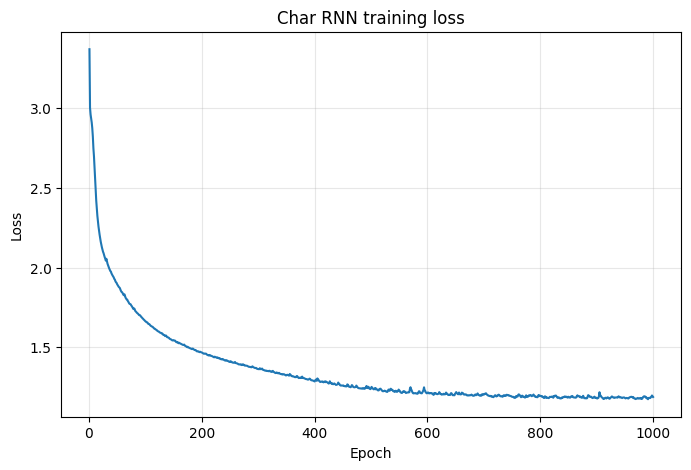

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(1, n_epoch + 1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Char RNN training loss')
plt.grid(True, alpha=0.3)
plt.show()

In [7]:
import numpy as np

MAX_LENGTH = 100

def generate_sample(char_rnn, seed_phrase=' Hello', max_length=MAX_LENGTH, temperature=1.0):
    '''
    ### Disclaimer: this is an example function for text generation.
    ### You can either adapt it in your code or create your own function

    The function generates text given a phrase of length at least SEQ_LENGTH.
    :param seed_phrase: prefix characters. The RNN is asked to continue the phrase
    :param max_length: maximum output length, including seed_phrase
    :param temperature: coefficient for sampling.  higher temperature produces more chaotic outputs,
        smaller temperature converges to the single most likely output.

    Be careful with the model output. This model waits logits (not probabilities/log-probabilities)
    of the next symbol.
    '''

    seed_phrase = seed_phrase.lower()
    x_sequence = [token_to_idx[token] for token in seed_phrase]
    x_sequence = torch.tensor([x_sequence], dtype=torch.int64)
    hid_state = char_rnn.initial_state(batch_size=1)

    #feed the seed phrase, if any
    for i in range(len(seed_phrase) - 1):
        out, hid_state = char_rnn(x_sequence[:, i], hid_state)

    #start generating
    for _ in range(max_length - len(seed_phrase)):
        out, hid_state = char_rnn(x_sequence[:, -1], hid_state)
        # Be really careful here with the model output
        p_next = F.softmax(out / temperature, dim=-1).data.numpy()[0]

        # sample next token and push it back into x_sequence
        next_ix = np.random.choice(len(tokens), p=p_next)
        next_ix = torch.tensor([[next_ix]], dtype=torch.int64)
        x_sequence = torch.cat([x_sequence, next_ix], dim=1)

    return ''.join([tokens[ix] for ix in x_sequence.data.numpy()[0]])

In [ ]:
# An example of generated text.
print(generate_sample(char_rnn=char_rnn, seed_phrase=' Hello', max_length=500, temperature=0.6))

 hellow, whis is heavend on the summer's de dost the strip
  how meat it the praise blath thee,
    and fort in tongs the despecked:
  the despiaintes my me
  dount to show cane to be,--
    but seest we their spires bure,
  where one shall not pire not bereathe, nor the spanty bread my seeming,
  what successity gried with a tormine hours make give:
  shall eake the worst of thy love ale sweet,
  though to feirnd with then whence the sparted from then, ot not bere doow.
  that thou well i ampre


### More poetic model

Let's use LSTM instead of vanilla RNN and compare the results.

Plot the loss function of the number of epochs. Does the final loss become better?

In [21]:
import torch
from torch import nn
from torch.nn import functional as F

class CharLSTM(nn.Module):
    def __init__(self, num_tokens=38, hidden_size=128):
        super(self.__class__, self).__init__()
        self.num_tokens = num_tokens
        self.hidden_size = hidden_size

        self.gates = nn.Linear(num_tokens + hidden_size, 4 * hidden_size)
        self.head = nn.Linear(hidden_size, num_tokens)

        with torch.no_grad():
            self.gates.bias[hidden_size:2 * hidden_size] = 1.

    def forward(self, x, state_prev):
        h_prev, c_prev = state_prev[:, :self.hidden_size], state_prev[:, self.hidden_size:]

        x_one_hot = F.one_hot(x, self.num_tokens).float()
        i, f, g, o = self.gates(torch.cat([x_one_hot, h_prev], dim=-1)).chunk(4, dim=-1)

        c_next = torch.sigmoid(f) * c_prev + torch.sigmoid(i) * torch.tanh(g)
        h_next = torch.sigmoid(o) * torch.tanh(c_next)

        logits = self.head(h_next)
        return logits, torch.cat([h_next, c_next], dim=-1)

    def initial_state(self, batch_size, device='cpu'):
        return torch.zeros(batch_size, 2 * self.hidden_size, device=device)

In [9]:
SEQ_LENGTH = 100
text_ids = torch.tensor([token_to_idx[token] for token in text], dtype=torch.int64)
n_chunks = len(text_ids) // (SEQ_LENGTH + 1)
chunks = text_ids[:n_chunks * (SEQ_LENGTH + 1)].view(n_chunks, SEQ_LENGTH + 1)

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
char_lstm = CharLSTM().to(device)
opt = torch.optim.Adam(char_lstm.parameters(), lr=2e-3)
loss_func = nn.CrossEntropyLoss()

n_epoch = 1000
batch_size = 128
loss_history = []

for epoch in range(n_epoch):
    perm = torch.randperm(n_chunks)
    epoch_loss, n_batches = 0., 0

    for start in range(0, n_chunks, batch_size):
        batch = chunks[perm[start:start + batch_size]].to(device)
        hid_state = char_lstm.initial_state(batch.shape[0], device=device)

        logits_seq = []
        for t in range(SEQ_LENGTH):
            logits, hid_state = char_lstm(batch[:, t], hid_state)
            logits_seq.append(logits)
        logits_seq = torch.stack(logits_seq, dim=1)

        loss = loss_func(logits_seq.reshape(-1, len(tokens)), batch[:, 1:].reshape(-1))

        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(char_lstm.parameters(), 5.)
        opt.step()

        epoch_loss += loss.item()
        n_batches += 1

    loss_history.append(epoch_loss / n_batches)
    print(f'epoch {epoch + 1:2d} | loss {loss_history[-1]:.4f}')

epoch  1 | loss 3.4106
epoch  2 | loss 3.0290
epoch  3 | loss 2.9796
epoch  4 | loss 2.9656
epoch  5 | loss 2.9548
epoch  6 | loss 2.9445
epoch  7 | loss 2.9311
epoch  8 | loss 2.9117
epoch  9 | loss 2.8841
epoch 10 | loss 2.8460
epoch 11 | loss 2.7986
epoch 12 | loss 2.7433
epoch 13 | loss 2.6811
epoch 14 | loss 2.6164
epoch 15 | loss 2.5510
epoch 16 | loss 2.4975
epoch 17 | loss 2.4526
epoch 18 | loss 2.4073
epoch 19 | loss 2.3715
epoch 20 | loss 2.3425
epoch 21 | loss 2.3113
epoch 22 | loss 2.2862
epoch 23 | loss 2.2635
epoch 24 | loss 2.2439
epoch 25 | loss 2.2251
epoch 26 | loss 2.2067
epoch 27 | loss 2.1901
epoch 28 | loss 2.1763
epoch 29 | loss 2.1611
epoch 30 | loss 2.1462
epoch 31 | loss 2.1359
epoch 32 | loss 2.1212
epoch 33 | loss 2.1080
epoch 34 | loss 2.0966
epoch 35 | loss 2.0877
epoch 36 | loss 2.0787
epoch 37 | loss 2.0661
epoch 38 | loss 2.0579
epoch 39 | loss 2.0475
epoch 40 | loss 2.0380
epoch 41 | loss 2.0289
epoch 42 | loss 2.0198
epoch 43 | loss 2.0117
epoch 44 | 

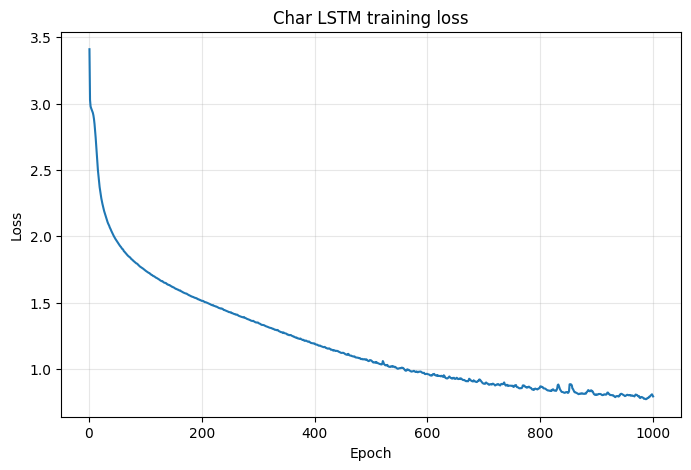

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(1, n_epoch + 1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Char LSTM training loss')
plt.grid(True, alpha=0.3)
plt.show()

Generate text using the trained net with different `temperature` parameter: `[0.1, 0.2, 0.5, 1.0, 2.0]`.

Evaluate the results visually, try to interpret them.

In [13]:
for temperature in [0.1, 0.2, 0.5, 1.0, 2.0]:
    print(generate_sample(char_lstm, seed_phrase=' Hello', max_length=500, temperature=temperature), end='\n')
    print('-----------------------------------------------------------------', end='\n')

 helloving hat that on the start
  and end the sweet of thy self alone.
  in other'd dieds must thou take thee a faintent
  iffect, of their waster's ride undrown-best,
  the ownod, that dost thou thy self are day?
  nor streagt, since offencex'd in the world
  and their dear love, whose shoulds of shame
  when sweet to the time, my heart thou art,
  so decay, and lose thee, which i am delight,
  and in the world, and they write thee more.

  xii

  with though nor to the to-mode, being arth,
  
-----------------------------------------------------------------
 helloving hat that on the starure,
  hanner nummer datil touthtile thy seart, if now with thou dong,
    and time thee ofears the eye is bless datence,
  and in the world i seek when they still doth stake:
  the wortceenter's from my love's state,
  and the best that i better the dead,
  the wilone eye which the unusse mide,
  there thou art mentenge more to petter;
  un is it! but from thee, be so far of many,
  san make sweet 

Чем выше температура, тем выше вероятность выбора менее релевантного с точки зрения модели следующего токена. Поэтому при высокой температуре встречается всё больше вымышленных слов.

### Saving and loading models

Save the model to the disk, then load it and generate text. Examples are available [here](https://pytorch.org/tutorials/beginner/saving_loading_models.html]).

In [14]:
torch.save({
    'state_dict': char_lstm.state_dict(),
    'num_tokens': char_lstm.num_tokens,
    'hidden_size': char_lstm.hidden_size,
    'tokens': tokens,
}, 'char_lstm.pt')

In [15]:
checkpoint = torch.load('char_lstm.pt', map_location=device)

char_lstm = CharLSTM(
    num_tokens=checkpoint['num_tokens'],
    hidden_size=checkpoint['hidden_size']
).to(device)
char_lstm.load_state_dict(checkpoint['state_dict'])
char_lstm.eval()

CharLSTM(
  (gates): Linear(in_features=166, out_features=512, bias=True)
  (head): Linear(in_features=128, out_features=38, bias=True)
)

In [17]:
print(generate_sample(char_lstm, seed_phrase=' Hello', max_length=500, temperature=0.2))

 helloving hat is suck of time doth propass date;
  but shall still and more that weal thee: 'thun 'will.
  thee i should it is not is with youth's
  to the seem doth presessede thy obeass,
  when i willy, and thou art being would a confine,
  but the sweets sometime, some wherefore more with did strive,
  against hisself-live stare all will should need
  that the limble leed one mine eyes, which they her aling,
  and dumbs and the strength of their mayst,
  the reath the best of a painted bear.


### References
1. <a href='http://karpathy.github.io/2015/05/21/rnn-effectiveness/'> Andrew Karpathy blog post about RNN. </a>
There are several examples of genration: Shakespeare texts, Latex formulas, Linux Sourse Code and children names.
2. <a href='https://github.com/karpathy/char-rnn'> Repo with char-rnn code </a>
3. Cool repo with PyTorch examples: [link](https://github.com/spro/practical-pytorch`)